# Walmart_Sales_Forecasting_System

## phase 1 : Data Loading & Understanding

In [6]:
# Import required libraries
import pandas as pd
import numpy as np
import os

# Define project data directory paths for easy saving/loading
RAW_DATA_PATH = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\raw\Walmart_Sales.csv"

# 1. Load the raw dataset
df = pd.read_csv(RAW_DATA_PATH)

# 2. View the first 5 rows of the dataset
print("--- First 5 Rows of Walmart Dataset ---")
print(df.head())

# 3. Inspect data structure and columns data types
print("\n--- Structural Information of Dataset ---")
print(df.info())

# 4. Check statistical distribution of numeric columns
print("\n--- Summary Statistics ---")
print(df.describe())


--- First 5 Rows of Walmart Dataset ---
   Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1  05-02-2010    1643690.90             0        42.31       2.572   
1      1  12-02-2010    1641957.44             1        38.51       2.548   
2      1  19-02-2010    1611968.17             0        39.93       2.514   
3      1  26-02-2010    1409727.59             0        46.63       2.561   
4      1  05-03-2010    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  

--- Structural Information of Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   We

In [7]:
# Data Cleaning & Datetime Conversion

# Import required libraries
import pandas as pd
import os

# 1. Define folder paths for saving checkpoint
processed_dir = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\processed"
os.makedirs(processed_dir, exist_ok=True)
processed_file_path = os.path.join(processed_dir, "walmart_processed.csv")

# 2. Convert Date column from string to datetime format
# The dataset has day-month-year format (e.g., 05-02-2010)
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# 3. Verify the data type change
print("--- Updated Column Data Types ---")
print(df.dtypes)

# 4. Save the checkpoint to the processed folder
df.to_csv(processed_file_path, index=False)
print(f"\n--- Success: Processed data saved to {processed_file_path} ---")


--- Updated Column Data Types ---
Store                    int64
Date            datetime64[us]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object

--- Success: Processed data saved to C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\processed\walmart_processed.csv ---


In [8]:
# Feature Engineering
# Import required libraries
import pandas as pd
import os

# 1. Define folder paths for saving the clean checkpoint
clean_dir = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean"
os.makedirs(clean_dir, exist_ok=True)
clean_file_path = os.path.join(clean_dir, "walmart_clean.csv")

# 2. Extract Year, Month, and Week of Year from the Date column
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week_Of_Year'] = df['Date'].dt.isocalendar().week.astype(int)

# 3. View the new columns along with Date to verify
print("--- Sample of New Features Created ---")
print(df[['Date', 'Year', 'Month', 'Week_Of_Year']].head())

# 4. Check the dataset shape to see new column count
print(f"\nNew Dataset Shape (Rows, Columns): {df.shape}")

# 5. Save the final clean dataset to the clean folder
df.to_csv(clean_file_path, index=False)
print(f"\n--- Success: Clean dataset saved to {clean_file_path} ---")


--- Sample of New Features Created ---
        Date  Year  Month  Week_Of_Year
0 2010-02-05  2010      2             5
1 2010-02-12  2010      2             6
2 2010-02-19  2010      2             7
3 2010-02-26  2010      2             8
4 2010-03-05  2010      3             9

New Dataset Shape (Rows, Columns): (6435, 11)

--- Success: Clean dataset saved to C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean\walmart_clean.csv ---


C:\Users\lenovo\AppData\Local\Temp\ipykernel_5488\2570101748.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Holiday_Flag', y='Weekly_Sales', data=avg_sales_holiday, palette='muted')
C:\Users\lenovo\AppData\Local\Temp\ipykernel_5488\2570101748.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Non-Holiday Week', 'Holiday Week'])


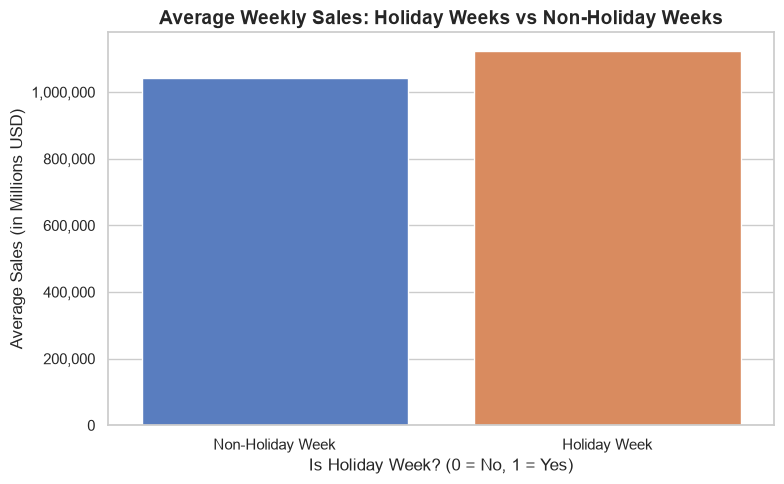

--- Exact Average Sales Figures ---
Average Sales on Non-Holiday Weeks: $1,041,256.38
Average Sales on Holiday Weeks:     $1,122,887.89


In [9]:
# Exploratory Data Analysis (EDA) & Visualization
# Holiday Impact Study
# Import required libraries for visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set plot style for a clean look
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# 2. Calculate average sales for Holiday vs Non-Holiday weeks
avg_sales_holiday = df.groupby('Holiday_Flag')['Weekly_Sales'].mean().reset_index()

# 3. Create a Bar Plot to compare sales
ax = sns.barplot(x='Holiday_Flag', y='Weekly_Sales', data=avg_sales_holiday, palette='muted')

# 4. Enhance the chart UI/UX (Labels, Title)
plt.title('Average Weekly Sales: Holiday Weeks vs Non-Holiday Weeks', fontsize=14, fontweight='bold')
plt.xlabel('Is Holiday Week? (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Average Sales (in Millions USD)', fontsize=12)
ax.set_xticklabels(['Non-Holiday Week', 'Holiday Week'])

# 5. Format y-axis to show clear numbers instead of scientific notation
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# 6. Show the graph
plt.tight_layout()
plt.show()

# 7. Print the exact numerical difference
print("--- Exact Average Sales Figures ---")
print(f"Average Sales on Non-Holiday Weeks: ${df[df['Holiday_Flag'] == 0]['Weekly_Sales'].mean():,.2f}")
print(f"Average Sales on Holiday Weeks:     ${df[df['Holiday_Flag'] == 1]['Weekly_Sales'].mean():,.2f}")


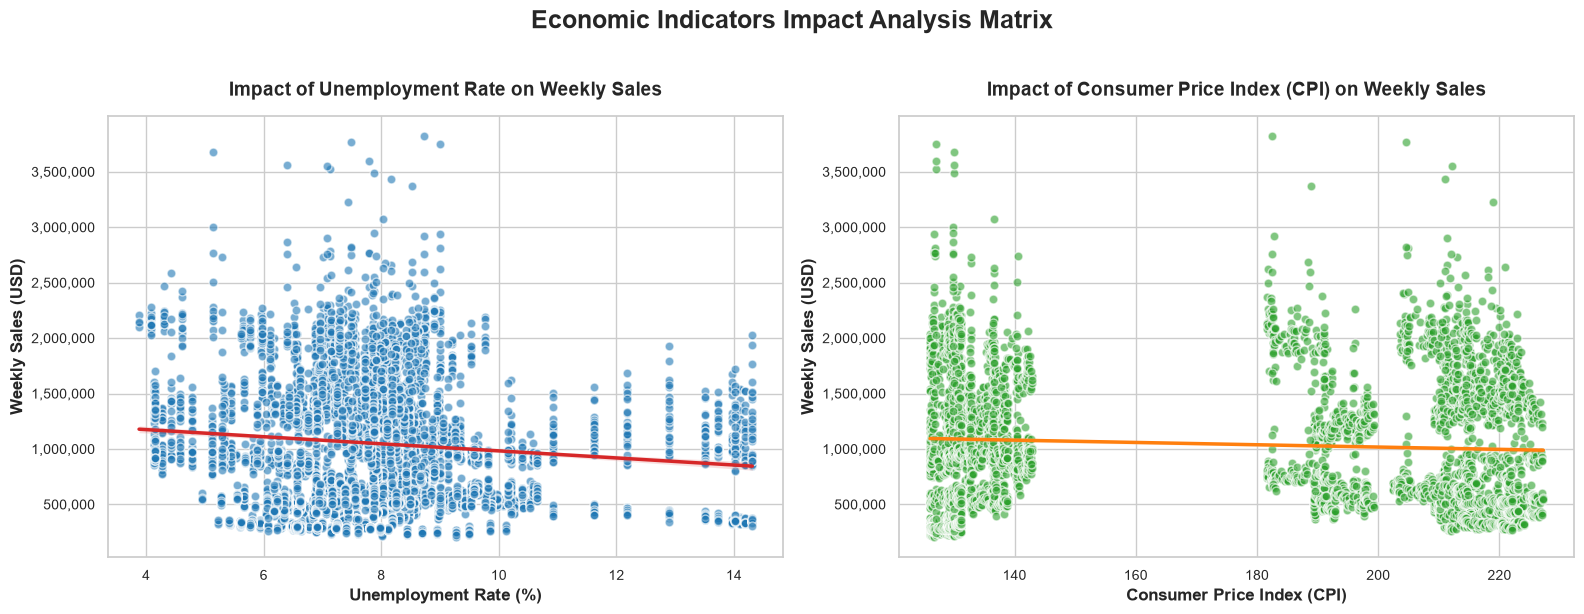

In [10]:
# Economic Indicators Study
# Import required libraries for advanced visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize a highly attractive multicolored grid with 2 subplots side-by-side
# We set a large figure size for high resolution and clean UI/UX
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="darkgrid") # Using high-contrast darkgrid style

# 2. Subplot 1: Unemployment vs Weekly Sales (Color theme: Coolwarm/Viridis style)
# Scatter plot with regression line to show the trend clearly
sns.regplot(
    x='Unemployment', 
    y='Weekly_Sales', 
    data=df, 
    ax=axes[0],
    scatter_kws={'alpha':0.6, 'color': '#1f77b4', 'edgecolor': 'w', 's': 40},
    line_kws={'color': '#d62728', 'linewidth': 2.5}
)
axes[0].set_title('Impact of Unemployment Rate on Weekly Sales', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Unemployment Rate (%)', fontsize=12, fontweight='semibold')
axes[0].set_ylabel('Weekly Sales (USD)', fontsize=12, fontweight='semibold')
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].tick_params(axis='both', which='major', labelsize=10)

# 3. Subplot 2: CPI vs Weekly Sales (Color theme: Plasma/Magma style)
# Scatter plot with regression line to understand macroeconomic correlation
sns.regplot(
    x='CPI', 
    y='Weekly_Sales', 
    data=df, 
    ax=axes[1],
    scatter_kws={'alpha':0.6, 'color': '#2ca02c', 'edgecolor': 'w', 's': 40},
    line_kws={'color': '#ff7f0e', 'linewidth': 2.5}
)
axes[1].set_title('Impact of Consumer Price Index (CPI) on Weekly Sales', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Consumer Price Index (CPI)', fontsize=12, fontweight='semibold')
axes[1].set_ylabel('Weekly Sales (USD)', fontsize=12, fontweight='semibold')
axes[1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[1].tick_params(axis='both', which='major', labelsize=10)

# 4. Final layout optimization to ensure titles and labels do not overlap
plt.suptitle('Economic Indicators Impact Analysis Matrix', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [11]:
# Machine Learning Model
# Import machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import joblib
import os

# 1. Select inputs (Features) and target variable
# We will use the original columns and our new engineered features
X = df[['Store', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Week_Of_Year']]
y = df['Weekly_Sales']

# 2. Split data into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Make predictions on the test dataset
y_pred = model.predict(X_test)

# 5. Calculate Regression Evaluation Metrics
r2_accuracy = metrics.r2_score(y_test, y_pred)
mae = metrics.mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))

print("--- Machine Learning Model Evaluation Metrics ---")
print(f"Model Accuracy (R2 Score): {r2_accuracy * 100:.2f}%")
print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")

# 6. Save the trained model to the processed folder for deployment
model_dir = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\processed"
model_path = os.path.join(model_dir, "walmart_linear_model.pkl")
joblib.dump(model, model_path)

print(f"\n--- Success: Trained model saved successfully to {model_path} ---")


--- Machine Learning Model Evaluation Metrics ---
Model Accuracy (R2 Score): 15.55%
Mean Absolute Error (MAE): $432,594.98
Root Mean Squared Error (RMSE): $521,583.50

--- Success: Trained model saved successfully to C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\processed\walmart_linear_model.pkl ---


In [15]:

# Import Random Forest Regressor and evaluation metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
import joblib
import os

# 1. Initialize the Random Forest Regressor Model
# n_estimators=100 means we are using 300 decision trees together
# random_state=42 ensures that the results are reproducible
rf_model = RandomForestRegressor(n_estimators=300, random_state=42)

# 2. Train the model using the training dataset
rf_model.fit(X_train, y_train)

# 3. Make predictions on the test dataset
y_pred_rf = rf_model.predict(X_test)

# 4. Calculate Evaluation Metrics for Random Forest
r2_accuracy_rf = metrics.r2_score(y_test, y_pred_rf)
mae_rf = metrics.mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(metrics.mean_squared_error(y_test, y_pred_rf))

print("--- Random Forest Regressor Model Evaluation Metrics ---")
print(f"Model Accuracy (R2 Score): {r2_accuracy_rf * 100:.2f}%")
print(f"Mean Absolute Error (MAE): ${mae_rf:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_rf:,.2f}")

# 5. Save this high-accuracy production model to the clean folder
clean_model_dir = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean"
production_model_path = os.path.join(clean_model_dir, "walmart_production_model.pkl")
joblib.dump(rf_model, production_model_path)

print(f"\n--- Success: Production model saved successfully to {production_model_path} ---")


--- Random Forest Regressor Model Evaluation Metrics ---
Model Accuracy (R2 Score): 96.03%
Mean Absolute Error (MAE): $61,760.75
Root Mean Squared Error (RMSE): $113,109.96

--- Success: Production model saved successfully to C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean\walmart_production_model.pkl ---


In [17]:
# Import XGBoost Regressor and evaluation metrics
from xgboost import XGBRegressor
from sklearn import metrics
import joblib
import os

# 1. Initialize the XGBoost Regressor Model
# n_estimators=100 means we are using 100 boosting trees
# learning_rate=0.1 controls how fast the model learns from past mistakes
# random_state=42 ensures the results are exactly reproducible
xgb_model = XGBRegressor(n_estimators=300, learning_rate=0.1, random_state=42)

# 2. Train the XGBoost model using the training dataset
xgb_model.fit(X_train, y_train)

# 3. Make predictions on the test dataset
y_pred_xgb = xgb_model.predict(X_test)

# 4. Calculate Evaluation Metrics for XGBoost
r2_accuracy_xgb = metrics.r2_score(y_test, y_pred_xgb)
mae_xgb = metrics.mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(metrics.mean_squared_error(y_test, y_pred_xgb))

print("--- XGBoost Regressor Model Evaluation Metrics ---")
print(f"Model Accuracy (R2 Score): {r2_accuracy_xgb * 100:.2f}%")
print(f"Mean Absolute Error (MAE): ${mae_xgb:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse_xgb:,.2f}")

# 5. Save the trained XGBoost model to the clean folder
clean_dir_xgb = r"C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean"
xgb_model_path = os.path.join(clean_dir_xgb, "walmart_xgboost_model.pkl")
joblib.dump(xgb_model, xgb_model_path)

print(f"\n--- Success: XGBoost model saved successfully to {xgb_model_path} ---")


--- XGBoost Regressor Model Evaluation Metrics ---
Model Accuracy (R2 Score): 97.79%
Mean Absolute Error (MAE): $49,635.36
Root Mean Squared Error (RMSE): $84,313.03

--- Success: XGBoost model saved successfully to C:\Users\lenovo\OneDrive\Desktop\Walmart_Sales_Forecasting_System\data\clean\walmart_xgboost_model.pkl ---
